In [1]:
from google.colab import files
uploaded = files.upload()

Saving fashion_sales.csv to fashion_sales.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("fashion_sales.csv")
df = df.drop_duplicates().dropna()

print(df.head())

         Date Product_ID Size Store_ID  Season  Units_Sold  \
0  2026-01-05       P001    S     ST01  Winter          25   
1  2026-01-06       P001    M     ST01  Winter          40   
2  2026-01-07       P001    L     ST01  Winter          35   
3  2026-01-08       P001   XL     ST01  Winter          20   
4  2026-01-10       P002    S     ST02  Winter          18   

  Customer_Demographics Return_Status  
0           Young Adult            No  
1           Young Adult            No  
2                 Adult           Yes  
3                 Adult           Yes  
4           Young Adult            No  


In [3]:
print(df.groupby("Size")["Units_Sold"].sum())
print(df.groupby("Season")["Units_Sold"].sum())
print(df.groupby("Store_ID")["Units_Sold"].sum())

Size
L     293
M     371
S     194
XL    140
Name: Units_Sold, dtype: int64
Season
Spring    125
Summer    570
Winter    303
Name: Units_Sold, dtype: int64
Store_ID
ST01    408
ST02    331
ST03    259
Name: Units_Sold, dtype: int64


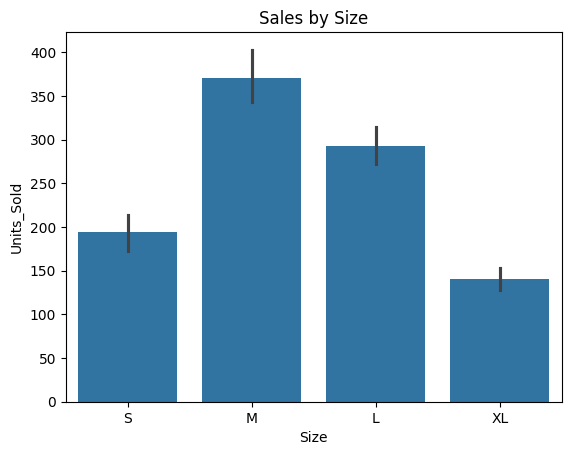

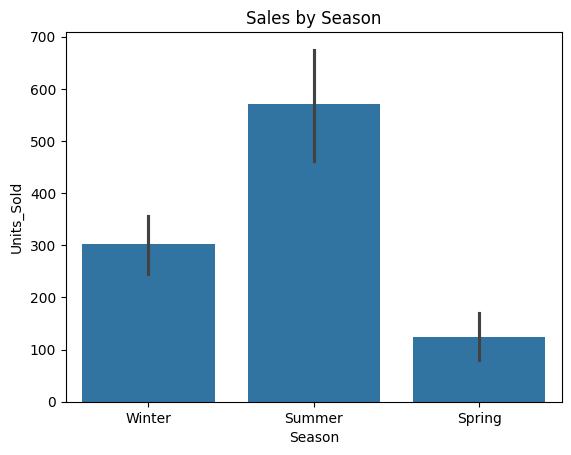

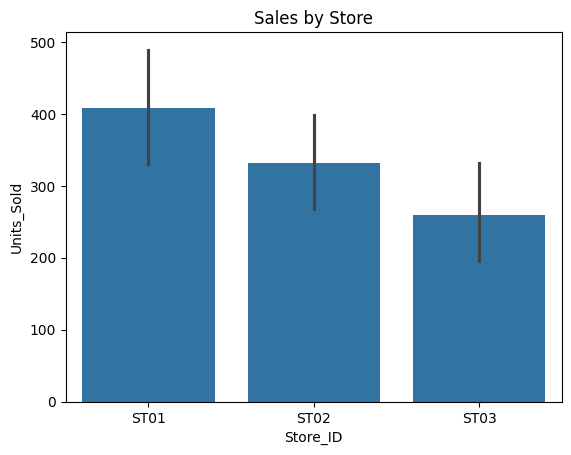

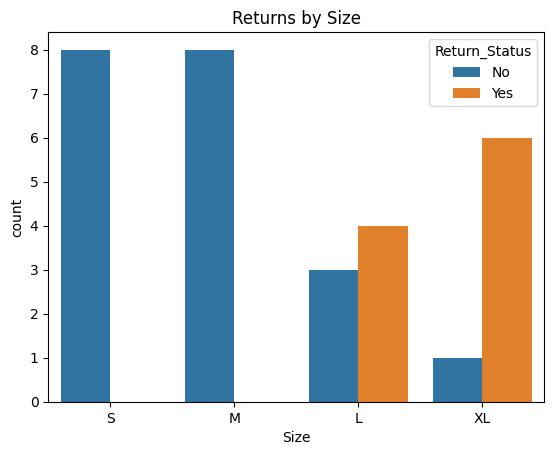

In [4]:
sns.barplot(data=df, x="Size", y="Units_Sold", estimator=sum)
plt.title("Sales by Size")
plt.show()

sns.barplot(data=df, x="Season", y="Units_Sold", estimator=sum)
plt.title("Sales by Season")
plt.show()

sns.barplot(data=df, x="Store_ID", y="Units_Sold", estimator=sum)
plt.title("Sales by Store")
plt.show()

sns.countplot(data=df, x="Size", hue="Return_Status")
plt.title("Returns by Size")
plt.show()

In [5]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

for col in ["Size","Store_ID","Season","Customer_Demographics","Return_Status"]:
    df[col] = LabelEncoder().fit_transform(df[col])

df["High_Demand"] = (df["Units_Sold"] >= df["Units_Sold"].mean()).astype(int)

X = df[["Size","Store_ID","Season","Customer_Demographics","Return_Status"]]
y = df["High_Demand"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))

Accuracy: 1.0
